# MySteth 2.0 — RQ7 (potential): zero-shot external validation on ZCHSound

**Question.** *Does the finished MySteth 2.0 system, trained only on CirCor, still separate children with congenital heart disease (CHD) from healthy children on an independent paediatric dataset, and do its two gates (SQA, confidence) still do their job there?*

Nothing is trained or tuned on ZCHSound. Every model, threshold and gate setting comes from CirCor (RQ1–RQ6).

### ZCHSound (Jia et al., IEEE TBME 2024)
- 1,259 children, **one recording each**, one site (2nd–3rd intercostal space, left sternal border), ChildCare G-100 stethoscope, 8 kHz, about 20 s.
- Labels: **echocardiography-confirmed diagnoses** reviewed by cardiac surgeons: Normal, VSD, ASD, PFO, PDA. There are no murmur labels.
- **Clean set:** 941 children aged 2 days to 14 years (Normal 533, VSD 187, ASD 119, PFO 70, PDA 32). **Noisy set:** 318 newborns aged 0–6 days (Normal 160, ASD 102, PFO 35, VSD 14, PDA 7), screened by physicians as containing noise.

### The five components here

| # | Component | In RQ7 |
|---|---|---|
| ① | SQA | The final SQA model (5 frozen encoders + 7 hand-crafted features, late fusion, threshold saved with it) scores every ZCHSound recording; failed → re-record |
| ②+③ | SSL + multi-task | The RQ3 system model (joint Domain-SSL), all 9 networks (3 folds × 3 seeds) |
| ④ | UQ | `ens_temp` with RQ3's temperatures; per task Chow risk; the RQ6 patient-level confidence gate (20 %) |
| ⑤ | XAI | not run (decisions are unchanged by XAI; RQ5 evaluated it) |

### Decisions fixed before writing this notebook

| Decision | Choice |
|---|---|
| Target | **CHD vs Normal** (any of VSD, ASD, PFO, PDA = CHD), as ZCHSound's own Task 1-1 / 2-1 |
| Primary predictor | **Murmur head** (probability of murmur Present); outcome head secondary |
| Evaluated set | All 1,259 children as the system would meet them; clean and noisy subsets reported separately, as a test of the gates |
| Zero-shot | Thresholds, temperatures and gate settings from CirCor only. ZCHSound audio is resampled to CirCor's 4 kHz before anything sees it |
| Combining the 9 networks | Per fold, `ens_temp` (mean of the 3 seeds' temperature-scaled probabilities); the 3 folds' probabilities averaged. Decision threshold = mean of the 3 folds' CirCor patient thresholds |
| Rows | no gates · SQA gate only · confidence gate only · full system (SQA gate, then confidence gate) |
| Confidence gate | As RQ6: the higher of the two tasks' Chow-risk percentiles; the top 20 % of the children reaching it deferred; ranked without labels and re-ranked in every bootstrap resample |
| Metrics | On automated decisions: AUC, F1 (macro), accuracy, weighted accuracy (CHD weight 5), sensitivity, specificity; workload shares; errors left; share of errors deferred. ECE is not reported: the heads predict murmur and clinical outcome, not CHD, so calibration against CHD labels is not defined |
| Statistics | 1,000 bootstrap resamples of children (seed 42); every row paired against the full system |
| Answer rule | Section 9, fixed here |

### Checks before any result
- ZCHSound counts match the paper exactly.
- The SQA hand-crafted features recomputed on 50 CirCor recordings equal the saved feature file; optionally, the 5 encoders reproduce the cached SQA embeddings.
- The downstream networks reproduce RQ3's saved CirCor window logits (max |Δ| < 0.05, as RQ5).

### Kaggle setup
- **GPU on, Internet on.** Add an `HF_TOKEN` secret (HeAR).
- Attach: **ZCHSound**; **CirCor v2** (for the checks); **RQ3 output** (`rq3_outputs`); the **SQA output** with `sqa_final_model.joblib`; **`sqa-helpers`** (`recording_features_full_v2.csv`); optionally the cached SQA embeddings.

In [1]:
!pip install -q panns_inference

In [2]:
import os, glob, time, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import joblib
import torch
import torch.nn as nn
import torchaudio
import torchaudio.transforms as T
from scipy.signal import resample_poly
from scipy.stats import rankdata
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
device = torch.device(DEVICE)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
NAVY, TEAL, ORANGE, RED, GRAY, PURPLE = "#1F3864", "#1F8A70", "#E67E22", "#C0392B", "#6B7280", "#7D3C98"
print("device:", DEVICE)


@dataclass
class Config:
    # ---- EDIT THESE PATHS to match your Kaggle inputs ----
    zch_root: str = "/kaggle/input/datasets/tusharrbb/zchsounds/ZCHSound"
    circor_root: str = "/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2"
    rq3_dir: str = "/kaggle/input/notebooks/tusharrbb/rq3-redone/rq3_outputs/"
    sqa_model_path: str = "/kaggle/input/models/tusharrbb/sqa-joblib/scikitlearn/default/1/sqa_final_model.joblib"
    sqa_features_path: str = "/kaggle/input/datasets/tusharrbb/sqa-helpers/recording_features_full_v2.csv"
    sqa_emb_cache: str = "/kaggle/input/datasets/tusharrbb/embeddings-sqa"          # optional: folder with emb_*.npy + emb_ids.csv from the SQA run
    output_dir: str = "/kaggle/working/rq7_outputs"

    # identical to RQ2–RQ6
    sample_rate: int = 4000
    n_fft: int = 256
    hop_length: int = 32
    n_mels: int = 64
    fmin: float = 20.0
    fmax: float = 800.0
    window_sec: float = 5.0
    hop_sec: float = 2.5
    embed_dim: int = 512
    dropout_p: float = 0.5
    n_folds: int = 3
    seeds: tuple = (42, 123, 7)
    n_boot: int = 1000
    budget: float = 0.20

    # checks
    n_check_features: int = 50
    n_check_windows: int = 200
    batch_size: int = 64

cfg = Config()
ZCH, R3 = Path(cfg.zch_root), Path(cfg.rq3_dir)
CIRCOR_AUDIO = Path(cfg.circor_root) / "training_data" / "training_data"
OUT = Path(cfg.output_dir); OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)
SYSTEM = "joint_domain"
TASKS = ["murmur", "outcome"]
TK = {"murmur": "m", "outcome": "o"}
for p_ in [ZCH, CIRCOR_AUDIO, Path(cfg.sqa_model_path), Path(cfg.sqa_features_path), R3 / "rq3_temperatures.csv",
           R3 / "rq3_thresholds.csv", R3 / "rq2_folds.csv", R3 / "rq2_windows.csv"]:
    assert p_.exists(), f"missing input: {p_}"
for f in range(cfg.n_folds):
    for s in cfg.seeds:
        assert (R3 / "models" / f"{SYSTEM}_f{f}_s{s}.pt").exists() and (R3 / "units" / f"{SYSTEM}_f{f}_s{s}.npz").exists()
print(cfg)

device: cuda
Config(zch_root='/kaggle/input/datasets/tusharrbb/zchsounds/ZCHSound', circor_root='/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2', rq3_dir='/kaggle/input/notebooks/tusharrbb/rq3-redone/rq3_outputs/', sqa_model_path='/kaggle/input/models/tusharrbb/sqa-joblib/scikitlearn/default/1/sqa_final_model.joblib', sqa_features_path='/kaggle/input/datasets/tusharrbb/sqa-helpers/recording_features_full_v2.csv', sqa_emb_cache='/kaggle/input/datasets/tusharrbb/embeddings-sqa', output_dir='/kaggle/working/rq7_outputs', sample_rate=4000, n_fft=256, hop_length=32, n_mels=64, fmin=20.0, fmax=800.0, window_sec=5.0, hop_sec=2.5, embed_dim=512, dropout_p=0.5, n_folds=3, seeds=(42, 123, 7), n_boot=1000, budget=0.2, n_check_features=50, n_check_windows=200, batch_size=64)


## 1. ZCHSound: recordings, labels, subsets

**Check:** 1,259 recordings, each found once on disk; diagnosis counts equal the paper's (clean: Normal 533, VSD 187, ASD 119, PFO 70, PDA 32; noisy: Normal 160, ASD 102, PFO 35, VSD 14, PDA 7).

In [3]:
path = sorted(ZCH.glob("*lean*Details*.csv"))
print("Files found:", path)

assert len(path) == 1, f"Expected one clean Details CSV, found {path}"

d = pd.read_csv(path[0], encoding="utf-8-sig")

print("\nFile:", path[0])
print("Shape:", d.shape)
print("Columns:", d.columns.tolist())
display(d.head())

Files found: [PosixPath('/kaggle/input/datasets/tusharrbb/zchsounds/ZCHSound/Clean Heartsound Data Details.csv')]

File: /kaggle/input/datasets/tusharrbb/zchsounds/ZCHSound/Clean Heartsound Data Details.csv
Shape: (941, 11)
Columns: ['fileName', 'gender', 'age(days)', 'diagnosis', '传感器', '采样率', '采集位置', '检查所见', '检查结论', '信号质量', '备注：说明没有其他心脏疾病，']


,fileName,gender,age(days),diagnosis,传感器,采样率,采集位置,检查所见,检查结论,信号质量,备注：说明没有其他心脏疾病，
0,ZCH0001.wav,M,2310,NORMAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ZCH0002.wav,M,3375,NORMAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ZCH0003.wav,M,2190,NORMAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ZCH0004.wav,M,2155,NORMAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ZCH0005.wav,M,2190,NORMAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
noisy_path = sorted(ZCH.glob("*oise*Details*.csv"))
print("Files found:", noisy_path)

assert len(noisy_path) == 1, f"Expected one noisy CSV, found {noisy_path}"

d_noisy = pd.read_csv(noisy_path[0], encoding="utf-8-sig")

print("Shape:", d_noisy.shape)
print("Columns:", d_noisy.columns.tolist())
display(d_noisy.head())

Files found: [PosixPath('/kaggle/input/datasets/tusharrbb/zchsounds/ZCHSound/Noise Heartsound Data Details.csv')]
Shape: (318, 1)
Columns: ['fileName;gender;age(days);diagnosis']


,fileName;gender;age(days);diagnosis
0,ZCH0942.wav;M;1;NORMAL
1,ZCH0943.wav;M;1;NORMAL
2,ZCH0944.wav;F;1;NORMAL
3,ZCH0945.wav;M;1;NORMAL
4,ZCH0946.wav;F;1;NORMAL


In [5]:
import shutil
import pandas as pd
from pathlib import Path

# Create a writable copy of the dataset
ZCH_FIXED = Path("/kaggle/working/ZCHSound")
shutil.copytree(ZCH, ZCH_FIXED, dirs_exist_ok=True)

# Fix the semicolon-delimited noisy CSV
noisy_file = next(ZCH_FIXED.glob("*oise*Details*.csv"))

df_noisy = pd.read_csv(noisy_file, sep=";", encoding="utf-8-sig")
df_noisy.to_csv(noisy_file, index=False, encoding="utf-8-sig")

# Redirect the original cell to the corrected copy
ZCH = ZCH_FIXED

print("Dataset copied and delimiter fixed!")
print("Working directory:", ZCH)
print("Noisy CSV columns:", pd.read_csv(noisy_file).columns.tolist())

Dataset copied and delimiter fixed!
Working directory: /kaggle/working/ZCHSound
Noisy CSV columns: ['fileName', 'gender', 'age(days)', 'diagnosis']


In [6]:
def read_details(pattern, subset):
    path = sorted(ZCH.glob(pattern))
    assert len(path) == 1, f"{pattern}: found {path}"
    d = pd.read_csv(path[0], encoding="utf-8-sig")
    d.columns = [c.strip() for c in d.columns]
    d = d[["fileName", "gender", "age(days)", "diagnosis"]].copy()
    d["subset"] = subset
    return d

zman = pd.concat([read_details("*lean*Details*.csv", "clean"), read_details("*oise*Details*.csv", "noisy")], ignore_index=True)
zman["fileName"] = zman.fileName.astype(str).str.strip()
zman["diagnosis"] = zman.diagnosis.astype(str).str.strip().str.upper()
wavs = {}
for p_ in ZCH.rglob("*.wav"):
    assert p_.name not in wavs, f"duplicate file name {p_.name}"
    wavs[p_.name] = p_
assert zman.fileName.is_unique and set(zman.fileName) <= set(wavs), "every listed recording must exist once on disk"
zman["path"] = zman.fileName.map(wavs)
zman["chd"] = (zman.diagnosis != "NORMAL").astype(int)
N = len(zman)

expected = {"clean": {"NORMAL": 533, "VSD": 187, "ASD": 119, "PFO": 70, "PDA": 32},
            "noisy": {"NORMAL": 160, "ASD": 102, "PFO": 35, "VSD": 14, "PDA": 7}}
for sub, exp in expected.items():
    got = zman[zman.subset == sub].diagnosis.value_counts().to_dict()
    assert got == exp, f"{sub}: diagnosis counts {got} differ from the paper {exp}"
assert N == 1259
print(f"ZCHSound: {N} children | CHD {zman.chd.sum()} ({zman.chd.mean():.1%})")
display(pd.crosstab(zman.diagnosis, zman.subset, margins=True))

ZCHSound: 1259 children | CHD 566 (45.0%)


subset,clean,noisy,All
diagnosis,,,
ASD,119,102,221
NORMAL,533,160,693
PDA,32,7,39
PFO,70,35,105
VSD,187,14,201
All,941,318,1259


## 2. Audio at CirCor's 4 kHz

Each recording is read, averaged to mono (some noisy recordings are stereo) and resampled from 8 kHz to 4 kHz, the rate every MySteth 2.0 component was built on. The same 4 kHz signal goes to the SQA features, the SQA encoders and the downstream model.

In [7]:
def load_zch(path):
    x, sr = sf.read(path, dtype="float32", always_2d=False)
    if x.ndim > 1:
        x = x.mean(axis=1)
    assert sr == 8000, (path, sr)
    return torchaudio.functional.resample(torch.from_numpy(np.ascontiguousarray(x)), sr, cfg.sample_rate).numpy().astype(np.float32)

ZAUDIO = [load_zch(p_) for p_ in tqdm(zman.path, desc="ZCHSound audio")]
zman["duration_s"] = [len(a) / cfg.sample_rate for a in ZAUDIO]
display(zman.groupby("subset").duration_s.describe().round(2))

ZCHSound audio:   0%|          | 0/1259 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
subset,,,,,,,,
clean,941.0,20.06,1.84,18.48,19.84,19.88,19.88,60.12
noisy,318.0,20.25,5.10,6.46,15.36,20.92,22.97,41.33


## 3. ① SQA on ZCHSound

The final SQA model is reused as saved: five logistic-regression probes, each on one frozen encoder's pooled embedding (mean ‖ max over windows) joined with the 7 hand-crafted features, averaged; recordings with `p_good` below its saved threshold are sent to re-record. The encoder and feature code below is copied from the SQA notebook.

**Checks:** the hand-crafted features recomputed on 50 random CirCor recordings must equal `recording_features_full_v2.csv`; if the SQA embedding cache is attached, each encoder must reproduce it on 5 CirCor recordings (cosine > 0.999).

In [8]:
HANDCRAFTED = ["rms_energy", "spectral_centroid", "spectral_bandwidth", "zcr", "clip_ratio", "silence_ratio", "periodicity_strength"]

def handcrafted(y, sr):
    # body identical to the SQA feature extraction (librosa defaults, native rate)
    rms = librosa.feature.rms(y=y).mean()
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr).mean()
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr).mean()
    zcr = librosa.feature.zero_crossing_rate(y).mean()
    peak = np.max(np.abs(y)) if len(y) else 0.0
    clip_ratio = np.mean(np.abs(y) > 0.98 * peak) if peak > 0 else 0.0
    silence_ratio = np.mean(np.abs(y) < 0.02)
    envelope = np.abs(librosa.util.normalize(y))
    envelope = librosa.util.frame(envelope, frame_length=int(sr * 0.02), hop_length=int(sr * 0.01)).mean(axis=0)
    if len(envelope) > 10:
        ac = np.correlate(envelope - envelope.mean(), envelope - envelope.mean(), mode="full")
        ac = ac[len(ac) // 2:]
        ac = ac / (ac[0] + 1e-8)
        hop_sec = 0.01
        min_lag, max_lag = int(60 / 220 / hop_sec), int(60 / 40 / hop_sec)
        max_lag = min(max_lag, len(ac) - 1)
        periodicity_strength = float(np.max(ac[min_lag:max_lag])) if max_lag > min_lag else 0.0
    else:
        periodicity_strength = 0.0
    return [rms, centroid, bandwidth, zcr, clip_ratio, silence_ratio, periodicity_strength]

# ---- check against the saved CirCor features ----
feat_ref = pd.read_csv(cfg.sqa_features_path)
feat_ref["wid"] = feat_ref.wav_path.astype(str).str.replace("\\", "/", regex=False).str.split("/").str[-1].str.replace(".wav", "", regex=False)
rng = np.random.default_rng(SEED)
chk_ids = rng.choice(feat_ref.wid.values, size=cfg.n_check_features, replace=False)
rows_chk = []
for wid in tqdm(chk_ids, desc="SQA feature check (CirCor)"):
    y, sr = librosa.load(CIRCOR_AUDIO / f"{wid}.wav", sr=None)
    rows_chk.append(handcrafted(y, sr))
mine = np.array(rows_chk, dtype=float)
ref = feat_ref.set_index("wid").loc[chk_ids, HANDCRAFTED].values.astype(float)
rel = np.abs(mine - ref) / (np.abs(ref) + 1e-9)
print("max relative difference per feature:", dict(zip(HANDCRAFTED, rel.max(0).round(6))))
assert np.allclose(mine, ref, rtol=1e-3, atol=1e-6), "hand-crafted features differ from recording_features_full_v2.csv: the feature code is not the one used for SQA"
print("SQA hand-crafted features reproduced on", cfg.n_check_features, "CirCor recordings")

ZHC = np.array([handcrafted(a, cfg.sample_rate) for a in tqdm(ZAUDIO, desc="ZCHSound hand-crafted features")], dtype=np.float32)

SQA feature check (CirCor):   0%|          | 0/50 [00:00<?, ?it/s]

max relative difference per feature: {'rms_energy': np.float64(0.0), 'spectral_centroid': np.float64(0.0), 'spectral_bandwidth': np.float64(0.0), 'zcr': np.float64(0.0), 'clip_ratio': np.float64(0.0), 'silence_ratio': np.float64(0.0), 'periodicity_strength': np.float64(1e-06)}
SQA hand-crafted features reproduced on 50 CirCor recordings


ZCHSound hand-crafted features:   0%|          | 0/1259 [00:00<?, ?it/s]

In [9]:
WIN_SEC, HOP_SEC, MIN_LAST_SEC = 10.0, 5.0, 3.0

def resample_from4k(x, target_sr):
    return resample_poly(x, target_sr // cfg.sample_rate, 1).astype(np.float32)

def windows(x, sr):
    w, h = int(WIN_SEC * sr), int(HOP_SEC * sr)
    if len(x) <= w:
        return [x]
    out = [x[s:s + w] for s in range(0, len(x) - w + 1, h)]
    last = (len(x) - w) // h * h + h
    if len(x) - last >= MIN_LAST_SEC * sr:
        out.append(x[last:])
    return out

def pool(mat):
    return np.concatenate([mat.mean(axis=0), mat.max(axis=0)])

def _as_tensor(out):
    if isinstance(out, torch.Tensor):
        return out
    for k in ("pooler_output", "audio_embeds", "last_hidden_state"):
        v = getattr(out, k, None)
        if v is not None:
            return v if v.dim() == 2 else v.mean(dim=1)
    return out[0]

PANNS_CKPT = Path.home() / "panns_data" / "Cnn14_mAP=0.431.pth"
PANNS_URL = "https://zenodo.org/records/3987831/files/Cnn14_mAP=0.431.pth?download=1"

def fetch_panns_checkpoint():
    import urllib.request
    if PANNS_CKPT.exists() and PANNS_CKPT.stat().st_size >= 3e8:
        return
    PANNS_CKPT.parent.mkdir(parents=True, exist_ok=True)
    tmp = PANNS_CKPT.with_suffix(".part")
    with urllib.request.urlopen(PANNS_URL) as r, open(tmp, "wb") as f, \
         tqdm(total=int(r.headers.get("Content-Length", 0)), unit="B", unit_scale=True, desc="PANNs checkpoint") as bar:
        while chunk := r.read(1 << 20):
            f.write(chunk); bar.update(len(chunk))
    tmp.replace(PANNS_CKPT)

class PANNsEncoder:
    sr, outputs = 32000, ["panns", "panns_probs"]
    def __init__(self):
        fetch_panns_checkpoint()
        from panns_inference import AudioTagging
        self.at = AudioTagging(checkpoint_path=None, device=DEVICE)
    @torch.no_grad()
    def __call__(self, x):
        e, p = [], []
        for w in windows(x, self.sr):
            clip, emb = self.at.inference(w[None, :])
            p.append(clip[0]); e.append(emb[0])
        return {"panns": pool(np.stack(e)), "panns_probs": pool(np.stack(p))}

class ASTEncoder:
    sr, outputs, NAME = 16000, ["ast"], "MIT/ast-finetuned-audioset-10-10-0.4593"
    def __init__(self):
        from transformers import ASTFeatureExtractor, ASTModel
        self.fe = ASTFeatureExtractor.from_pretrained(self.NAME)
        self.m = ASTModel.from_pretrained(self.NAME).to(DEVICE).eval()
    @torch.no_grad()
    def __call__(self, x):
        inp = self.fe(windows(x, self.sr), sampling_rate=self.sr, return_tensors="pt").to(DEVICE)
        return {"ast": pool(self.m(**inp).pooler_output.float().cpu().numpy())}

class CLAPEncoder:
    sr, outputs, NAME = 48000, ["clap"], "laion/clap-htsat-unfused"
    def __init__(self):
        from transformers import ClapFeatureExtractor, ClapModel
        self.fe = ClapFeatureExtractor.from_pretrained(self.NAME)
        self.m = ClapModel.from_pretrained(self.NAME).to(DEVICE).eval()
    @torch.no_grad()
    def __call__(self, x):
        inp = self.fe(windows(x, self.sr), sampling_rate=self.sr, return_tensors="pt",
                      truncation="rand_trunc", padding="repeatpad").to(DEVICE)
        return {"clap": pool(_as_tensor(self.m.get_audio_features(**inp)).float().cpu().numpy())}

class HeAREncoder:
    sr, outputs, CLIP, HOP = 16000, ["hear"], 32000, 16000
    def __init__(self):
        import tensorflow as tf
        for g in tf.config.list_physical_devices("GPU"):
            tf.config.experimental.set_memory_growth(g, True)
        from huggingface_hub import snapshot_download, login
        from kaggle_secrets import UserSecretsClient
        login(token=UserSecretsClient().get_secret("HF_TOKEN"))
        self.tf = tf
        self.fn = tf.saved_model.load(snapshot_download("google/hear")).signatures["serving_default"]
    def clips(self, x):
        if len(x) <= self.CLIP:
            return [np.pad(x, (0, self.CLIP - len(x)))]
        starts = list(range(0, len(x) - self.CLIP + 1, self.HOP))
        if len(x) - (starts[-1] + self.CLIP) >= self.sr:
            starts.append(len(x) - self.CLIP)
        return [x[s:s + self.CLIP] for s in starts]
    def __call__(self, x):
        c = np.stack(self.clips(x)).astype(np.float32)
        return {"hear": pool(self.fn(x=self.tf.constant(c))["output_0"].numpy())}

# ---- embed ZCHSound (and, if the cache is attached, check each encoder on 5 CirCor recordings) ----
cache = Path(cfg.sqa_emb_cache) if cfg.sqa_emb_cache else None
if cache is not None:
    print("Hi I am here 1")
    cache_ids = pd.read_csv(cache / "emb_ids.csv").wid.tolist()
    emb_chk_ids = list(np.random.default_rng(SEED).choice(cache_ids, size=5, replace=False))
ZEMB = {}
print("Hi I am here 2")
for cls in [PANNsEncoder, ASTEncoder, CLAPEncoder, HeAREncoder]:
    t0, enc = time.time(), cls()
    if cache is not None:
        for k in cls.outputs:
            ref_e = np.load(cache / f"emb_{k}.npy")[[cache_ids.index(w) for w in emb_chk_ids]]
            new_e = []
            for w in emb_chk_ids:
                x, sr = sf.read(CIRCOR_AUDIO / f"{w}.wav", dtype="float32", always_2d=False)
                new_e.append(enc(resample_from4k(x if x.ndim == 1 else x.mean(1), enc.sr))[k])
            new_e = np.stack(new_e)
            cos = (ref_e * new_e).sum(1) / (np.linalg.norm(ref_e, axis=1) * np.linalg.norm(new_e, axis=1) + 1e-12)
            print(f"  {k}: cosine with cached SQA embeddings, min {cos.min():.5f}")
            assert cos.min() > 0.999, f"{k}: encoder does not reproduce the SQA embeddings"
    rows_e = {k: [] for k in cls.outputs}
    for a in tqdm(ZAUDIO, desc=cls.__name__, mininterval=2):
        for k, v in enc(resample_from4k(a, enc.sr)).items():
            rows_e[k].append(v)
    for k, v in rows_e.items():
        ZEMB[k] = np.stack(v).astype(np.float32)
        np.save(OUT / f"zch_emb_{k}.npy", ZEMB[k])
    print(f"{cls.__name__}: {time.time() - t0:.0f}s")
    del enc
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

Hi I am here 1
Hi I am here 2


PANNs checkpoint:   0%|          | 0.00/327M [00:00<?, ?B/s]

--2026-11-01 01:29:43--  http://storage.googleapis.com/us_audioset/youtube_corpus/v1/csv/class_labels_indices.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.184.207, 173.194.193.207, 192.178.129.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.184.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14675 (14K) [application/octet-stream]
Saving to: ‘/root/panns_data/class_labels_indices.csv’

     0K .......... ....                                       100%  132M=0s

2026-11-01 01:29:43 (132 MB/s) - ‘/root/panns_data/class_labels_indices.csv’ saved [14675/14675]



Checkpoint path: /root/panns_data/Cnn14_mAP=0.431.pth
GPU number: 2
  panns: cosine with cached SQA embeddings, min 1.00000
  panns_probs: cosine with cached SQA embeddings, min 1.00000


PANNsEncoder:   0%|          | 0/1259 [00:00<?, ?it/s]

PANNsEncoder: 224s


... (21 outputs left out)

I0000 00:00:1793497472.006359      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13264 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793497472.009966      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1793497482.431064     239 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  hear: cosine with cached SQA embeddings, min 1.00000


HeAREncoder:   0%|          | 0/1259 [00:00<?, ?it/s]

HeAREncoder: 605s


In [10]:
bundle = joblib.load(cfg.sqa_model_path)
assert bundle["handcrafted"] == HANDCRAFTED, "the saved SQA model uses a different hand-crafted feature order"
member_p = {}
for name, mem in bundle["members"].items():
    X = np.hstack([ZEMB[mem["encoder"]], ZHC]).astype(np.float32)
    member_p[name] = mem["model"].predict_proba(X)[:, 1]
zman["p_good"] = np.mean(list(member_p.values()), axis=0)
SQA_THRESHOLD = float(bundle["threshold"])
zman["sqa_pass"] = zman.p_good >= SQA_THRESHOLD
print(f"SQA members: {list(member_p)} | saved threshold {SQA_THRESHOLD}")
display(zman.groupby("subset").agg(children=("p_good", "size"), median_p_good=("p_good", "median"), pass_rate=("sqa_pass", "mean")).round(3))

SQA members: ['panns+hc', 'panns_probs+hc', 'ast+hc', 'clap+hc', 'hear+hc'] | saved threshold 0.55


,children,median_p_good,pass_rate
subset,,,
clean,941,0.936,0.982
noisy,318,0.923,0.991


## 4. ②③④ The system model on ZCHSound

The 9 RQ3 networks score every 5 s window (2.5 s hop, plus a final window), exactly as on CirCor. Per fold, the 3 seeds' window probabilities are temperature-scaled with RQ3's temperatures and averaged per recording (`ens_temp`); the 3 folds are then averaged. The decision threshold is the mean of the 3 folds' CirCor patient thresholds.

**Check:** on 200 random CirCor windows, every network reproduces RQ3's saved logits (max |Δ| < 0.05).

In [11]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch))
    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)

class SmallResNetEncoder(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 32, 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(32),
                                  nn.ReLU(inplace=True), nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = nn.Sequential(ResBlock(32, 64), ResBlock(64, 64))
        self.layer2 = nn.Sequential(ResBlock(64, 128, stride=2), ResBlock(128, 128))
        self.layer3 = nn.Sequential(ResBlock(128, 256, stride=2), ResBlock(256, 256))
        self.layer4 = nn.Sequential(ResBlock(256, embed_dim, stride=2), ResBlock(embed_dim, embed_dim))
        self.pool = nn.AdaptiveAvgPool2d(1)
    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.pool(x).flatten(1)

class LinearDropoutHead(nn.Module):
    def __init__(self, embed_dim, n_classes, dropout_p=cfg.dropout_p):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout_p)
        self.fc = nn.Linear(embed_dim, n_classes)
    def forward(self, x):
        return self.fc(self.dropout(x))

class JointNet(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.head_m = LinearDropoutHead(cfg.embed_dim, 2)
        self.head_o = LinearDropoutHead(cfg.embed_dim, 2)
    def forward(self, spec):
        e = self.encoder(spec)
        return self.head_m(e), self.head_o(e)

def load_net(f, s):
    net = JointNet(SmallResNetEncoder(cfg.embed_dim))
    net.load_state_dict(torch.load(R3 / "models" / f"{SYSTEM}_f{f}_s{s}.pt", map_location="cpu"))
    return net.to(device).eval()

WIN = int(cfg.window_sec * cfg.sample_rate)
HOP = int(cfg.hop_sec * cfg.sample_rate)
mel_tf = T.MelSpectrogram(sample_rate=cfg.sample_rate, n_fft=cfg.n_fft, hop_length=cfg.hop_length,
                          n_mels=cfg.n_mels, f_min=cfg.fmin, f_max=cfg.fmax, power=2.0).to(device)
db_tf = T.AmplitudeToDB(stype="power").to(device)

def window_starts(L):
    if L <= WIN:
        return [0]
    s = list(range(0, L - WIN + 1, HOP))
    if s[-1] + WIN < L:
        s.append(L - WIN)
    return s

def crop(a, s):
    w = a[s:s + WIN]
    return w if len(w) == WIN else np.pad(w, (0, WIN - len(w)))

@torch.no_grad()
def logits(net, crops):
    zm, zo = [], []
    for k in range(0, len(crops), cfg.batch_size):
        x = torch.from_numpy(np.stack(crops[k:k + cfg.batch_size])).to(device)
        lm, lo = net(db_tf(mel_tf(x)).unsqueeze(1))
        zm.append((lm[:, 1] - lm[:, 0]).cpu().numpy()); zo.append((lo[:, 1] - lo[:, 0]).cpu().numpy())
    return np.concatenate(zm), np.concatenate(zo)

# ---- check: reproduce RQ3's saved CirCor window logits ----
cman = pd.read_csv(R3 / "rq2_folds.csv")
w2 = pd.read_csv(R3 / "rq2_windows.csv")
chk_w = np.sort(np.random.default_rng(SEED).choice(len(w2), size=cfg.n_check_windows, replace=False))
caudio = {}
chk_crops = []
for j in chk_w:
    wid = w2.wid.iloc[j]
    if wid not in caudio:
        x, sr = torchaudio.load(str(CIRCOR_AUDIO / f"{wid}.wav"))
        x = x.mean(0) if x.shape[0] > 1 else x[0]
        assert sr == cfg.sample_rate
        caudio[wid] = x.numpy().astype(np.float32)
    chk_crops.append(crop(caudio[wid], int(w2.start_sample.iloc[j])))
worst = 0.0
for f in range(cfg.n_folds):
    for s in cfg.seeds:
        net = load_net(f, s)
        zm, zo = logits(net, chk_crops)
        u = np.load(R3 / "units" / f"{SYSTEM}_f{f}_s{s}.npz")
        worst = max(worst, np.abs(zm - u["z_det_m"][chk_w]).max(), np.abs(zo - u["z_det_o"][chk_w]).max())
        del net
assert worst < 0.05, f"networks do not reproduce RQ3's logits (max |Δ| {worst:.4f})"
print(f"RQ3 window logits reproduced on {cfg.n_check_windows} CirCor windows (max |Δ| {worst:.1e})")

RQ3 window logits reproduced on 200 CirCor windows (max |Δ| 6.4e-06)


In [12]:
TEMP3 = pd.read_csv(R3 / "rq3_temperatures.csv"); TEMP3 = TEMP3[TEMP3.model == SYSTEM]
THR3 = pd.read_csv(R3 / "rq3_thresholds.csv"); THR3 = THR3[(THR3.model == SYSTEM) & (THR3.method == "ens_temp")]
Tm = {(r.task, int(r.fold), int(r.seed)): float(r.temperature) for r in TEMP3.itertuples()}

zcrops, zrec = [], []
for i, a in enumerate(ZAUDIO):
    for s0 in window_starts(len(a)):
        zcrops.append(crop(a, s0)); zrec.append(i)
zrec = np.array(zrec)
counts = np.bincount(zrec, minlength=N)
first = np.r_[0, np.cumsum(counts)[:-1]]
rec_mean = lambda v: np.add.reduceat(v, first) / counts
print(f"ZCHSound windows: {len(zcrops)} (median {int(np.median(counts))} per recording)")

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

FOLD_P = {t: [] for t in TASKS}
for f in range(cfg.n_folds):
    per_seed = {t: [] for t in TASKS}
    for s in cfg.seeds:
        net = load_net(f, s)
        zm, zo = logits(net, zcrops)
        for t, z in [("murmur", zm), ("outcome", zo)]:
            per_seed[t].append(rec_mean(sigmoid(z / Tm[(t, f, s)])))
        del net
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    for t in TASKS:
        FOLD_P[t].append(np.mean(per_seed[t], 0))
P, THR = {}, {}
for t in TASKS:
    P[t] = np.mean(FOLD_P[t], 0)
    fold_thr = [float(THR3[(THR3.task == t) & (THR3.fold == f)].threshold_patient.iloc[0]) for f in range(cfg.n_folds)]
    THR[t] = float(np.mean(fold_thr))
    zman[f"p_{t}"] = P[t]
    zman[f"pred_{t}"] = (P[t] >= THR[t]).astype(int)
    print(f"{t}: CirCor fold thresholds {fold_thr} -> {THR[t]:.3f}; between-fold spread of probabilities (mean SD) {np.std(FOLD_P[t], 0).mean():.3f}")

def chow_risk(p, t):
    return np.where(p < t, p / t, (1 - p) / (1 - t))
RISK = {t: chow_risk(P[t], THR[t]) for t in TASKS}

ZCHSound windows: 9184 (median 7 per recording)
murmur: CirCor fold thresholds [0.35, 0.37, 0.5] -> 0.407; between-fold spread of probabilities (mean SD) 0.082
outcome: CirCor fold thresholds [0.47, 0.4, 0.37] -> 0.413; between-fold spread of probabilities (mean SD) 0.069


## 5. The pipelines on ZCHSound

| Row | ① SQA gate | confidence gate (20 % of the children reaching it) |
|---|---|---|
| no gates | off | off |
| SQA gate only | on | off |
| confidence gate only | off | on |
| **full system** | on | on |

The confidence gate is the RQ6 gate: each task's Chow risk becomes a percentile among the children reaching the gate, a child's combined risk is the higher of the two, and the top 20 % are deferred (ties broken by a fixed random number). The ranking uses no labels and is redone in every bootstrap resample.

In [13]:
ROWS = {"no gates": (False, False), "SQA gate only": (True, False), "confidence gate only": (False, True), "full system": (True, True)}
ROW_NAMES = list(ROWS)
TIEB = np.random.default_rng(SEED).random(N)
PASS = zman.sqa_pass.values

def deferral(name, ix):
    sqa_on, gate_on = ROWS[name]
    covered = PASS[ix] if sqa_on else np.ones(len(ix), bool)
    d = np.zeros(len(ix), bool)
    if not gate_on:
        return covered, d
    reach = np.flatnonzero(covered)
    pct = [rankdata(RISK[t][ix][reach]) / len(reach) for t in TASKS]
    comb = np.maximum(pct[0], pct[1])
    k = int(round(cfg.budget * len(reach)))
    d[reach[np.lexsort((TIEB[ix][reach], -comb))[:k]]] = True
    return covered, d

ALL_IX = np.arange(N)
DEF0 = {name: deferral(name, ALL_IX) for name in ROW_NAMES}
wl = []
for name in ROW_NAMES:
    cov, d = DEF0[name]
    for sub in ["all", "clean", "noisy"]:
        m = np.ones(N, bool) if sub == "all" else (zman.subset.values == sub)
        wl.append({"row": name, "subset": sub, "children": int(m.sum()), "re-record": np.mean(~cov[m]),
                   "clinician": np.mean(d[m]), "automated": np.mean(cov[m] & ~d[m])})
workload = pd.DataFrame(wl)
display(workload.pivot_table(index="row", columns="subset", values=["re-record", "clinician", "automated"], sort=False).round(3))

re-record               clinician               automated              
subset                     all  clean  noisy       all  clean  noisy       all  clean  noisy
row                                                                                         
no gates                 0.000  0.000  0.000     0.000  0.000  0.000     1.000  1.000  1.000
SQA gate only            0.016  0.018  0.009     0.000  0.000  0.000     0.984  0.982  0.991
confidence gate only     0.000  0.000  0.000     0.200  0.201  0.198     0.800  0.799  0.802
full system              0.016  0.018  0.009     0.197  0.198  0.195     0.787  0.784  0.796

## 6. Metrics and bootstrap

Per row, head (murmur primary, outcome secondary) and subset (all, clean, noisy), on the automated decisions: AUC, F1 (macro), accuracy, weighted accuracy (CHD weight 5), sensitivity, specificity; plus workload, errors left in automated decisions and the share of errors deferred (descriptive). 1,000 bootstrap resamples of children; the gate is re-ranked inside each resample on the pooled set, as at screening.

In [14]:
def auc_fast(y, s):
    n1 = int(np.sum(y == 1)); n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(s)
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

HEADS = ["murmur", "outcome"]
SUBSETS = ["all", "clean", "noisy"]
M_LIST = ["re-record", "clinician", "automated", "AUC", "F1 (macro)", "Accuracy", "Weighted accuracy", "Sensitivity", "Specificity",
          "Errors left in automated decisions", "Share of errors deferred"]
Y = zman.chd.values
SUB = zman.subset.values

def metrics(name, head, sub, ix, cov, dfr):
    m = np.ones(len(ix), bool) if sub == "all" else (SUB[ix] == sub)
    y, p = Y[ix][m], P[head][ix][m]
    yhat = (p >= THR[head]).astype(int)
    c, d = cov[m], dfr[m]
    auto = c & ~d
    ya, pa, ha = y[auto], p[auto], yhat[auto]
    tp = int(np.sum((ha == 1) & (ya == 1))); tn = int(np.sum((ha == 0) & (ya == 0)))
    fp = int(np.sum((ha == 1) & (ya == 0))); fn = int(np.sum((ha == 0) & (ya == 1)))
    P_, N_ = tp + fn, tn + fp
    f1s = []
    if P_ + fp > 0:
        f1s.append(2 * tp / (2 * tp + fp + fn))
    if N_ + fn > 0:
        f1s.append(2 * tn / (2 * tn + fp + fn))
    err = c & (yhat != y)
    return {"re-record": np.mean(~c), "clinician": np.mean(d), "automated": np.mean(auto),
            "AUC": auc_fast(ya, pa), "F1 (macro)": np.mean(f1s) if f1s else np.nan,
            "Accuracy": (tp + tn) / len(ya) if len(ya) else np.nan,
            "Weighted accuracy": (5 * tp + tn) / (5 * P_ + N_) if len(ya) else np.nan,
            "Sensitivity": tp / P_ if P_ else np.nan, "Specificity": tn / N_ if N_ else np.nan,
            "Errors left in automated decisions": float((err & auto).sum()),
            "Share of errors deferred": (err & d).sum() / err.sum() if ROWS[name][1] and err.sum() else np.nan}

POINT = {(n, h, s): metrics(n, h, s, ALL_IX, *DEF0[n]) for n in ROW_NAMES for h in HEADS for s in SUBSETS}
rng_boot = np.random.default_rng(SEED)
BIS = [rng_boot.choice(N, size=N, replace=True) for _ in range(cfg.n_boot)]
store = {k: [] for k in POINT}
for ix in tqdm(BIS, desc="bootstrap (gate re-ranked in every resample)"):
    dd = {n: deferral(n, ix) for n in ROW_NAMES}
    for n in ROW_NAMES:
        for h in HEADS:
            for s in SUBSETS:
                store[(n, h, s)].append(metrics(n, h, s, ix, *dd[n]))
BOOT = {k: pd.DataFrame(v) for k, v in store.items()}

def fmt(metric, v, lo, hi):
    if metric in ("re-record", "clinician", "automated"):
        return f"{v:.1%} [{lo:.1%}, {hi:.1%}]"
    if metric.startswith("Errors"):
        return f"{v:.0f} [{lo:.0f}, {hi:.0f}]"
    return f"{v:.3f} [{lo:.3f}, {hi:.3f}]"

res = []
for (n, h, s), pt in POINT.items():
    for metric in M_LIST:
        b = BOOT[(n, h, s)][metric].values.astype(float)
        v = pt[metric]
        lo, hi = (np.nanpercentile(b, 2.5), np.nanpercentile(b, 97.5)) if np.isfinite(b).any() else (np.nan, np.nan)
        res.append({"row": n, "head": h, "subset": s, "metric": metric, "value": v, "ci_low": lo, "ci_high": hi,
                    "cell": fmt(metric, v, lo, hi) if np.isfinite(v) else "—"})
results = pd.DataFrame(res)
for h in HEADS:
    for s in SUBSETS:
        print(f"\n=== {h} head vs CHD — {s} ===")
        t_ = results[(results["head"] == h) & (results["subset"] == s)].pivot_table(index="row", columns="metric", values="cell", aggfunc="first", sort=False)
        display(t_[M_LIST])

bootstrap (gate re-ranked in every resample):   0%|          | 0/1000 [00:00<?, ?it/s]


=== murmur head vs CHD — all ===


metric,re-record,clinician,automated,AUC,F1 (macro),Accuracy,Weighted accuracy,Sensitivity,Specificity,Errors left in automated decisions,Share of errors deferred
row,,,,,,,,,,,
no gates,"0.0% [0.0%, 0.0%]","0.0% [0.0%, 0.0%]","100.0% [100.0%, 100.0%]","0.767 [0.739, 0.793]","0.653 [0.624, 0.682]","0.706 [0.683, 0.732]","0.477 [0.444, 0.512]","0.350 [0.309, 0.390]","0.997 [0.993, 1.000]","370 [338, 399]",—
SQA gate only,"1.6% [1.0%, 2.3%]","0.0% [0.0%, 0.0%]","98.4% [97.7%, 99.0%]","0.773 [0.746, 0.799]","0.660 [0.632, 0.688]","0.713 [0.689, 0.738]","0.485 [0.453, 0.520]","0.358 [0.317, 0.398]","0.997 [0.992, 1.000]","356 [324, 385]",—
confidence gate only,"0.0% [0.0%, 0.0%]","20.0% [20.0%, 20.0%]","80.0% [80.0%, 80.0%]","0.749 [0.715, 0.779]","0.672 [0.642, 0.704]","0.721 [0.694, 0.749]","0.499 [0.463, 0.538]","0.374 [0.329, 0.420]","1.000 [1.000, 1.000]","281 [253, 308]","0.241 [0.205, 0.278]"
full system,"1.6% [1.0%, 2.3%]","19.7% [19.5%, 19.8%]","78.7% [78.2%, 79.3%]","0.756 [0.723, 0.786]","0.679 [0.649, 0.711]","0.729 [0.702, 0.757]","0.508 [0.471, 0.548]","0.383 [0.339, 0.430]","1.000 [1.000, 1.000]","269 [242, 295]","0.244 [0.208, 0.282]"



=== murmur head vs CHD — clean ===


metric,re-record,clinician,automated,AUC,F1 (macro),Accuracy,Weighted accuracy,Sensitivity,Specificity,Errors left in automated decisions,Share of errors deferred
row,,,,,,,,,,,
no gates,"0.0% [0.0%, 0.0%]","0.0% [0.0%, 0.0%]","100.0% [100.0%, 100.0%]","0.827 [0.797, 0.855]","0.738 [0.706, 0.767]","0.772 [0.744, 0.798]","0.585 [0.545, 0.625]","0.478 [0.430, 0.523]","0.996 [0.990, 1.000]","215 [190, 242]",—
SQA gate only,"1.8% [1.0%, 2.7%]","0.0% [0.0%, 0.0%]","98.2% [97.3%, 99.0%]","0.838 [0.810, 0.865]","0.749 [0.718, 0.777]","0.781 [0.754, 0.807]","0.599 [0.559, 0.637]","0.492 [0.443, 0.540]","0.996 [0.990, 1.000]","202 [178, 229]",—
confidence gate only,"0.0% [0.0%, 0.0%]","20.1% [18.8%, 21.5%]","79.9% [78.5%, 81.2%]","0.821 [0.787, 0.855]","0.759 [0.727, 0.791]","0.787 [0.759, 0.816]","0.612 [0.569, 0.657]","0.511 [0.457, 0.565]","1.000 [1.000, 1.000]","160 [138, 182]","0.256 [0.207, 0.313]"
full system,"1.8% [1.0%, 2.7%]","19.8% [18.5%, 21.2%]","78.4% [76.9%, 79.9%]","0.834 [0.802, 0.865]","0.772 [0.739, 0.803]","0.799 [0.771, 0.827]","0.629 [0.585, 0.673]","0.529 [0.473, 0.583]","1.000 [1.000, 1.000]","148 [127, 170]","0.267 [0.214, 0.326]"



=== murmur head vs CHD — noisy ===


... (3 outputs left out)


=== outcome head vs CHD — clean ===


metric,re-record,clinician,automated,AUC,F1 (macro),Accuracy,Weighted accuracy,Sensitivity,Specificity,Errors left in automated decisions,Share of errors deferred
row,,,,,,,,,,,
no gates,"0.0% [0.0%, 0.0%]","0.0% [0.0%, 0.0%]","100.0% [100.0%, 100.0%]","0.738 [0.703, 0.772]","0.601 [0.569, 0.632]","0.601 [0.570, 0.632]","0.680 [0.645, 0.715]","0.725 [0.681, 0.765]","0.507 [0.465, 0.549]","375 [344, 406]",—
SQA gate only,"1.8% [1.0%, 2.7%]","0.0% [0.0%, 0.0%]","98.2% [97.3%, 99.0%]","0.745 [0.708, 0.779]","0.605 [0.572, 0.636]","0.605 [0.573, 0.636]","0.686 [0.650, 0.720]","0.734 [0.688, 0.773]","0.509 [0.468, 0.551]","365 [334, 396]",—
confidence gate only,"0.0% [0.0%, 0.0%]","20.1% [18.8%, 21.5%]","79.9% [78.5%, 81.2%]","0.726 [0.686, 0.765]","0.612 [0.575, 0.645]","0.612 [0.575, 0.645]","0.656 [0.614, 0.696]","0.682 [0.630, 0.731]","0.558 [0.510, 0.605]","292 [264, 321]","0.221 [0.182, 0.255]"
full system,"1.8% [1.0%, 2.7%]","19.8% [18.5%, 21.2%]","78.4% [76.9%, 79.9%]","0.734 [0.691, 0.774]","0.616 [0.579, 0.650]","0.617 [0.580, 0.651]","0.663 [0.619, 0.704]","0.691 [0.638, 0.740]","0.561 [0.514, 0.609]","283 [255, 312]","0.225 [0.184, 0.261]"



=== outcome head vs CHD — noisy ===


metric,re-record,clinician,automated,AUC,F1 (macro),Accuracy,Weighted accuracy,Sensitivity,Specificity,Errors left in automated decisions,Share of errors deferred
row,,,,,,,,,,,
no gates,"0.0% [0.0%, 0.0%]","0.0% [0.0%, 0.0%]","100.0% [100.0%, 100.0%]","0.549 [0.481, 0.617]","0.547 [0.490, 0.600]","0.566 [0.510, 0.620]","0.429 [0.366, 0.496]","0.361 [0.284, 0.437]","0.769 [0.704, 0.830]","138 [118, 160]",—
SQA gate only,"0.9% [0.0%, 2.2%]","0.0% [0.0%, 0.0%]","99.1% [97.8%, 100.0%]","0.547 [0.484, 0.618]","0.545 [0.489, 0.599]","0.565 [0.510, 0.619]","0.426 [0.362, 0.492]","0.357 [0.281, 0.436]","0.772 [0.708, 0.836]","137 [116, 159]",—
confidence gate only,"0.0% [0.0%, 0.0%]","19.8% [15.4%, 23.5%]","80.2% [76.5%, 84.6%]","0.500 [0.424, 0.581]","0.497 [0.436, 0.563]","0.557 [0.496, 0.621]","0.336 [0.275, 0.416]","0.221 [0.153, 0.309]","0.865 [0.800, 0.921]","113 [93, 134]","0.181 [0.121, 0.248]"
full system,"0.9% [0.0%, 2.2%]","19.5% [15.1%, 23.3%]","79.6% [75.7%, 83.9%]","0.502 [0.423, 0.577]","0.498 [0.434, 0.559]","0.557 [0.494, 0.620]","0.336 [0.272, 0.411]","0.221 [0.149, 0.306]","0.870 [0.805, 0.924]","112 [93, 133]","0.182 [0.119, 0.247]"


In [15]:
# for h in HEADS:
#     for s in SUBSETS:
#         print(f"\n=== {h} head vs CHD — {s} ===")
#         t_ = results[(results["head"] == h) & (results["subset"] == s)].pivot_table(index="row", columns="metric", values="cell", aggfunc="first", sort=False)
#         display(t_[M_LIST])

## 7. Do the gates still do their job? (paired differences and gate checks)

- **Row − full system** on the same resamples, for both heads and every subset. "worse" / "better" = the system without that gate, when the 95 % CI excludes 0.
- **SQA against ZCHSound's own quality split:** AUROC of `p_good` for clean vs noisy recordings, and the pass rate in each subset.
- **Confidence gate:** AUROC of each head's Chow risk for its own errors, among the children reaching the gate (full system).

In [16]:
DIFF_M = ["AUC", "F1 (macro)", "Accuracy", "Weighted accuracy", "Sensitivity", "Specificity", "Errors left in automated decisions"]
diff_rows = []
for n in ROW_NAMES:
    if n == "full system":
        continue
    for h in HEADS:
        for s in SUBSETS:
            for metric in DIFF_M:
                a, b = POINT[(n, h, s)][metric], POINT[("full system", h, s)][metric]
                if not (np.isfinite(a) and np.isfinite(b)):
                    continue
                bd = BOOT[(n, h, s)][metric].values.astype(float) - BOOT[("full system", h, s)][metric].values.astype(float)
                lo, hi = np.nanpercentile(bd, 2.5), np.nanpercentile(bd, 97.5)
                lower_better = metric.startswith("Errors")
                if metric.startswith("Errors"):
                    verdict = "—"
                elif lo > 0:
                    verdict = "better"
                elif hi < 0:
                    verdict = "worse"
                else:
                    verdict = "n.s."
                cell = (f"{a - b:+.0f} [{lo:+.0f}, {hi:+.0f}]" if metric.startswith("Errors") else f"{a - b:+.3f} [{lo:+.3f}, {hi:+.3f}]")
                diff_rows.append({"row": n, "head": h, "subset": s, "metric": metric, "difference": a - b, "ci_low": lo, "ci_high": hi,
                                  "verdict": verdict, "cell": cell + ("" if verdict in ("n.s.", "—") else f" {verdict}")})
diffs = pd.DataFrame(diff_rows)
for h in HEADS:
    print(f"\n=== {h} head: row − full system (all children) ===")
    display(diffs[(diffs["head"] == h) & (diffs["subset"] == "all")].pivot_table(index="row", columns="metric", values="cell", aggfunc="first", sort=False)[DIFF_M])

# SQA vs ZCHSound's clean / noisy split
clean = (SUB == "clean").astype(int)
gate_rows = []
v = auc_fast(clean, zman.p_good.values)
b = np.array([auc_fast(clean[ix], zman.p_good.values[ix]) for ix in BIS])
gate_rows.append({"check": "SQA p_good: AUROC for clean vs noisy recordings", "value": v,
                  "ci_low": np.nanpercentile(b, 2.5), "ci_high": np.nanpercentile(b, 97.5)})
for s in ["clean", "noisy"]:
    m = SUB == s
    v = PASS[m].mean()
    b = np.array([PASS[ix][SUB[ix] == s].mean() for ix in BIS])
    gate_rows.append({"check": f"SQA pass rate, {s}", "value": v, "ci_low": np.nanpercentile(b, 2.5), "ci_high": np.nanpercentile(b, 97.5)})
cov_f, _ = DEF0["full system"]
for h in HEADS:
    err = (zman[f"pred_{h}"].values != Y)
    v = auc_fast(err[cov_f].astype(int), RISK[h][cov_f])
    b = np.array([auc_fast(err[ix][PASS[ix]].astype(int), RISK[h][ix][PASS[ix]]) for ix in BIS])
    gate_rows.append({"check": f"Chow risk ({h} head): AUROC for its own errors, children reaching the gate",
                      "value": v, "ci_low": np.nanpercentile(b, 2.5), "ci_high": np.nanpercentile(b, 97.5)})
gate_checks = pd.DataFrame(gate_rows)
gate_checks["value (95% CI)"] = [f"{r.value:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]" for r in gate_checks.itertuples()]
display(gate_checks[["check", "value (95% CI)"]])


=== murmur head: row − full system (all children) ===


metric,AUC,F1 (macro),Accuracy,Weighted accuracy,Sensitivity,Specificity,Errors left in automated decisions
row,,,,,,,
no gates,"+0.011 [-0.005, +0.026]","-0.027 [-0.042, -0.011] worse","-0.022 [-0.036, -0.009] worse","-0.031 [-0.050, -0.012] worse","-0.033 [-0.054, -0.011] worse","-0.003 [-0.007, +0.000]","+101 [+86, +118]"
SQA gate only,"+0.016 [+0.003, +0.030] better","-0.020 [-0.034, -0.005] worse","-0.016 [-0.029, -0.003] worse","-0.023 [-0.041, -0.006] worse","-0.025 [-0.045, -0.004] worse","-0.003 [-0.008, +0.000]","+87 [+72, +102]"
confidence gate only,"-0.008 [-0.014, +0.001]","-0.008 [-0.013, -0.002] worse","-0.008 [-0.013, -0.002] worse","-0.009 [-0.017, -0.003] worse","-0.009 [-0.016, -0.002] worse","+0.000 [+0.000, +0.000]","+12 [+5, +19]"



=== outcome head: row − full system (all children) ===


metric,AUC,F1 (macro),Accuracy,Weighted accuracy,Sensitivity,Specificity,Errors left in automated decisions
row,,,,,,,
no gates,"+0.018 [+0.006, +0.032] better","-0.004 [-0.019, +0.011]","-0.009 [-0.023, +0.006]","+0.038 [+0.022, +0.052] better","+0.064 [+0.045, +0.081] better","-0.067 [-0.086, -0.047] worse","+118 [+101, +133]"
SQA gate only,"+0.021 [+0.010, +0.032] better","-0.002 [-0.016, +0.012]","-0.007 [-0.020, +0.008]","+0.040 [+0.026, +0.054] better","+0.067 [+0.050, +0.082] better","-0.064 [-0.083, -0.044] worse","+107 [+91, +121]"
confidence gate only,"-0.003 [-0.010, +0.004]","-0.003 [-0.008, +0.002]","-0.004 [-0.009, +0.001]","-0.003 [-0.010, +0.004]","-0.003 [-0.011, +0.006]","-0.003 [-0.010, +0.002]","+10 [+4, +16]"


,check,value (95% CI)
0,SQA p_good: AUROC for clean vs noisy recordings,"0.551 [0.515, 0.586]"
1,"SQA pass rate, clean","0.982 [0.973, 0.990]"
2,"SQA pass rate, noisy","0.991 [0.978, 1.000]"
3,Chow risk (murmur head): AUROC for its own err...,"0.645 [0.610, 0.678]"
4,Chow risk (outcome head): AUROC for its own er...,"0.662 [0.634, 0.691]"


## 8. By diagnosis

Share of children called murmur **Present** by the murmur head, per diagnosis: with no gates (all children) and in the full system (among its automated decisions), with the share of each diagnosis that the full system decides automatically. For Normal children, "called Present" is a false alarm.

In [17]:
DX = ["NORMAL", "VSD", "ASD", "PFO", "PDA"]
DXV = zman.diagnosis.values
pred_m = zman.pred_murmur.values
cov_f, d_f = DEF0["full system"]
auto_f = cov_f & ~d_f

def dx_stats(ix, auto):
    out = {}
    for dx in DX:
        m = DXV[ix] == dx
        a = auto[m]
        out[f"{dx}|called Present, no gates"] = pred_m[ix][m].mean()
        out[f"{dx}|automated in full system"] = a.mean()
        out[f"{dx}|called Present among automated"] = pred_m[ix][m][a].mean() if a.any() else np.nan
    return out

pt_dx = dx_stats(ALL_IX, auto_f)
bs_dx = []
for ix in tqdm(BIS, desc="by diagnosis"):
    c, d = deferral("full system", ix)
    bs_dx.append(dx_stats(ix, c & ~d))
B = pd.DataFrame(bs_dx)
dx_rows = []
for dx in DX:
    row = {"diagnosis": dx, "children": int((DXV == dx).sum()), "clean": int(((DXV == dx) & (SUB == "clean")).sum()),
           "noisy": int(((DXV == dx) & (SUB == "noisy")).sum())}
    for q in ["called Present, no gates", "automated in full system", "called Present among automated"]:
        v = pt_dx[f"{dx}|{q}"]; b = B[f"{dx}|{q}"].values.astype(float)
        row[q] = f"{v:.1%} [{np.nanpercentile(b, 2.5):.1%}, {np.nanpercentile(b, 97.5):.1%}]"
    dx_rows.append(row)
by_dx = pd.DataFrame(dx_rows)
display(by_dx)

by diagnosis:   0%|          | 0/1000 [00:00<?, ?it/s]

,diagnosis,children,clean,noisy,"called Present, no gates",automated in full system,called Present among automated
0,NORMAL,693,533,160,"0.3% [0.0%, 0.7%]","80.1% [78.3%, 82.0%]","0.0% [0.0%, 0.0%]"
1,VSD,201,187,14,"78.6% [73.0%, 84.3%]","85.1% [79.9%, 89.8%]","84.2% [78.7%, 89.3%]"
2,ASD,221,119,102,"10.9% [7.0%, 15.2%]","71.9% [66.4%, 77.5%]","6.3% [2.6%, 10.1%]"
3,PFO,105,70,35,"1.0% [0.0%, 3.2%]","75.2% [65.7%, 82.4%]","0.0% [0.0%, 0.0%]"
4,PDA,39,32,7,"38.5% [23.1%, 54.3%]","69.2% [55.5%, 83.3%]","48.1% [27.8%, 66.7%]"


In [18]:
# ---------------------------------------------------------------------------
# 8b. EXPLORATORY: lesion groups (not part of the pre-set answer rule)
# Murmur head, no gates unless stated. Uses zman, P, THR, Y, SUB, N, BIS, auc_fast, DEF0, OUT.
# ---------------------------------------------------------------------------
DX_ORDER = ["NORMAL", "VSD", "PDA", "ASD", "PFO"]
DXV = zman.diagnosis.values
PM = P["murmur"]
YHAT = (PM >= THR["murmur"]).astype(int)
SUBS = {"all": np.ones(N, bool), "clean": SUB == "clean", "noisy": SUB == "noisy"}
GROUPS = {"VSD+PDA vs NORMAL": ["VSD", "PDA"], "ASD+PFO vs NORMAL": ["ASD", "PFO"]}

# A. Called Present and median p_murmur, per subset x diagnosis (no gates)
rows = []
for s, ms in SUBS.items():
    for dx in DX_ORDER:
        m = ms & (DXV == dx)
        rows.append({"subset": s, "diagnosis": dx, "children": int(m.sum()),
                     "called Present": int(YHAT[m].sum()),
                     "called Present (%)": round(100 * YHAT[m].mean(), 1) if m.any() else np.nan,
                     "median p_murmur": round(float(np.median(PM[m])), 3) if m.any() else np.nan})
lesion_counts = pd.DataFrame(rows)

# B. AUC of p_murmur, lesion group vs NORMAL; 95% CI from the same child resamples (BIS)
rows = []
for s, ms in SUBS.items():
    for gname, g in GROUPS.items():
        keep = ms & np.isin(DXV, g + ["NORMAL"])
        point = auc_fast(Y[keep], PM[keep])
        boots = [auc_fast(Y[ix][keep[ix]], PM[ix][keep[ix]]) for ix in BIS]
        lo, hi = np.nanpercentile(boots, [2.5, 97.5])
        rows.append({"subset": s, "comparison": gname,
                     "lesion children": int((keep & (Y == 1)).sum()), "normal children": int((keep & (Y == 0)).sum()),
                     "AUC": point, "ci_low": lo, "ci_high": hi, "AUC (95% CI)": f"{point:.3f} [{lo:.3f}, {hi:.3f}]"})
lesion_auc = pd.DataFrame(rows)

# C. Murmur-head errors by diagnosis at three levels
cov_f, d_f = DEF0["full system"]
LEVELS = {"all children (no gates)": np.ones(N, bool),
          "passed SQA (no confidence gate)": zman.sqa_pass.values.astype(bool),
          "automated in full system": cov_f & ~d_f}
err = YHAT != Y
rows = []
for lvl, ml in LEVELS.items():
    for dx in DX_ORDER + ["total"]:
        m = ml if dx == "total" else ml & (DXV == dx)
        rows.append({"level": lvl, "diagnosis": dx, "children": int(m.sum()), "murmur-head errors": int((err & m).sum())})
lesion_errors = pd.DataFrame(rows)

print("EXPLORATORY - not part of the pre-set answer rule")
display(lesion_counts.pivot_table(index="diagnosis", columns="subset", values=["children", "called Present", "median p_murmur"], aggfunc="first",
                                  sort=False).reindex(DX_ORDER))
display(lesion_auc[["subset", "comparison", "lesion children", "normal children", "AUC (95% CI)"]])
display(lesion_errors.pivot_table(index="diagnosis", columns="level", values="murmur-head errors", aggfunc="first", sort=False)
        .reindex(DX_ORDER + ["total"]))

lesion_counts.to_csv(OUT / "rq7_lesions_counts.csv", index=False)
lesion_auc.to_csv(OUT / "rq7_lesions_auc.csv", index=False)
lesion_errors.to_csv(OUT / "rq7_lesions_errors.csv", index=False)
print("saved: rq7_lesions_counts.csv, rq7_lesions_auc.csv, rq7_lesions_errors.csv")

EXPLORATORY - not part of the pre-set answer rule


children             called Present             median p_murmur              
subset         all clean noisy            all clean noisy             all  clean  noisy
diagnosis                                                                              
NORMAL         693   533   160              2     2     0           0.058  0.053  0.074
VSD            201   187    14            158   158     0           0.898  0.928  0.120
PDA             39    32     7             15    15     0           0.329  0.394  0.178
ASD            221   119   102             24    21     3           0.094  0.132  0.078
PFO            105    70    35              1     1     0           0.098  0.081  0.122

,subset,comparison,lesion children,normal children,AUC (95% CI)
0,all,VSD+PDA vs NORMAL,240,693,"0.923 [0.897, 0.949]"
1,all,ASD+PFO vs NORMAL,326,693,"0.652 [0.612, 0.689]"
2,clean,VSD+PDA vs NORMAL,219,533,"0.946 [0.922, 0.967]"
3,clean,ASD+PFO vs NORMAL,189,533,"0.690 [0.643, 0.733]"
4,noisy,VSD+PDA vs NORMAL,21,160,"0.667 [0.524, 0.812]"
5,noisy,ASD+PFO vs NORMAL,137,160,"0.556 [0.486, 0.628]"


level,all children (no gates),passed SQA (no confidence gate),automated in full system
diagnosis,,,
NORMAL,2,2,0
VSD,43,41,27
PDA,24,24,14
ASD,197,189,149
PFO,104,100,79
total,370,356,269


saved: rq7_lesions_counts.csv, rq7_lesions_auc.csv, rq7_lesions_errors.csv


## 9. The answer rule, applied

Murmur head (primary), all 1,259 children; outcome head reported the same way.

| question | condition (95 % CIs) |
|---|---|
| **Does the system transfer?** | AUC of the murmur head for CHD, no gates, above 0.5 |
| **Does the SQA gate still work?** | `p_good` separates ZCHSound's clean from noisy recordings (AUROC above 0.5) |
| **Does each gate still contribute?** | removing it from the full system makes at least one of AUC, F1 and weighted accuracy worse and none better (*contributes*); the reverse is *harmful*; both *mixed*; neither *no measurable contribution* |

In [19]:
RULE_M = ["AUC", "F1 (macro)", "Weighted accuracy"]

def gate_verdict(row, head):
    d = diffs[(diffs["row"] == row) & (diffs["head"] == head) & (diffs["subset"] == "all") & diffs["metric"].isin(RULE_M)]
    w, b = (d.verdict == "worse").sum(), (d.verdict == "better").sum()
    return "contributes" if w and not b else "harmful" if b and not w else "mixed" if w and b else "no measurable contribution"

ans = []
for h in HEADS:
    r = results[(results["row"] == "no gates") & (results["head"] == h) & (results["subset"] == "all") & (results["metric"] == "AUC")].iloc[0]
    ans.append({"head": h, "question": "transfers (AUC, no gates, above 0.5)", "answer": bool(r.ci_low > 0.5), "evidence": r.cell})
    ans.append({"head": h, "question": "SQA gate contributes (full − SQA gate)", "answer": gate_verdict("confidence gate only", h), "evidence": ""})
    ans.append({"head": h, "question": "confidence gate contributes (full − confidence gate)", "answer": gate_verdict("SQA gate only", h), "evidence": ""})
sq = gate_checks.iloc[0]
ans.append({"head": "—", "question": "SQA separates clean from noisy (AUROC above 0.5)", "answer": bool(sq.ci_low > 0.5), "evidence": sq["value (95% CI)"]})
answer = pd.DataFrame(ans)
display(answer)

,head,question,answer,evidence
0,murmur,"transfers (AUC, no gates, above 0.5)",True,"0.767 [0.739, 0.793]"
1,murmur,SQA gate contributes (full − SQA gate),contributes,
2,murmur,confidence gate contributes (full − confidence...,mixed,
3,outcome,"transfers (AUC, no gates, above 0.5)",True,"0.668 [0.635, 0.700]"
4,outcome,SQA gate contributes (full − SQA gate),no measurable contribution,
5,outcome,confidence gate contributes (full − confidence...,harmful,
6,—,SQA separates clean from noisy (AUROC above 0.5),True,"0.551 [0.515, 0.586]"


## 10. Figures

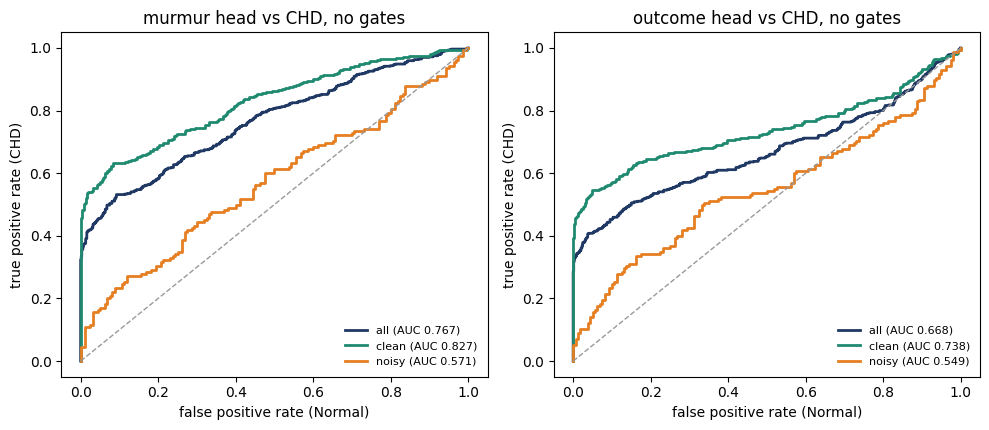

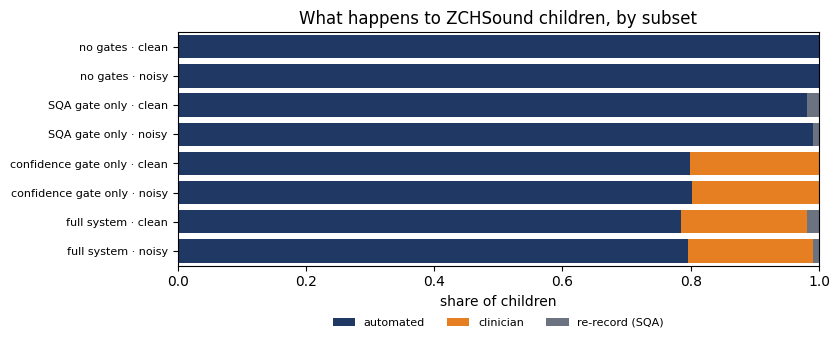

In [20]:
def roc_xy(y, s):
    o = np.argsort(-s); y = y[o]
    tpr = np.r_[0, np.cumsum(y) / max(y.sum(), 1)]; fpr = np.r_[0, np.cumsum(1 - y) / max((1 - y).sum(), 1)]
    return fpr, tpr

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, h in zip(axes, HEADS):
    for s, c in [("all", NAVY), ("clean", TEAL), ("noisy", ORANGE)]:
        m = np.ones(N, bool) if s == "all" else (SUB == s)
        fpr, tpr = roc_xy(Y[m], P[h][m])
        a = POINT[("no gates", h, s)]["AUC"]
        ax.plot(fpr, tpr, color=c, lw=2, label=f"{s} (AUC {a:.3f})")
    ax.plot([0, 1], [0, 1], color="#999999", lw=1, ls="--")
    ax.set(title=f"{h} head vs CHD, no gates", xlabel="false positive rate (Normal)", ylabel="true positive rate (CHD)")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "rq7_roc.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(8.5, 3.6))
labels_ = [f"{n} · {s}" for n in ROW_NAMES for s in ["clean", "noisy"]]
w_ = workload[workload.subset != "all"].set_index(["row", "subset"])
au = [w_.loc[(n, s), "automated"] for n in ROW_NAMES for s in ["clean", "noisy"]]
cl = [w_.loc[(n, s), "clinician"] for n in ROW_NAMES for s in ["clean", "noisy"]]
rr = [w_.loc[(n, s), "re-record"] for n in ROW_NAMES for s in ["clean", "noisy"]]
y_ = np.arange(len(labels_))
ax.barh(y_, au, color=NAVY, label="automated"); ax.barh(y_, cl, left=au, color=ORANGE, label="clinician")
ax.barh(y_, rr, left=np.add(au, cl), color=GRAY, label="re-record (SQA)")
ax.set_yticks(y_); ax.set_yticklabels(labels_, fontsize=8); ax.set_ylim(len(labels_) - 0.5, -0.5); ax.set_xlim(0, 1)
ax.set(title="What happens to ZCHSound children, by subset", xlabel="share of children")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.tight_layout(); plt.savefig(FIG_DIR / "rq7_workload.png", dpi=200); plt.show()

## 11. Save

| file | contents |
|---|---|
| `rq7_children.csv` | per child: subset, diagnosis, CHD, SQA `p_good` and pass, murmur and outcome probabilities and decisions, Chow risks, full-system deferral |
| `rq7_workload.csv`, `rq7_results.csv`, `rq7_differences.csv`, `rq7_gate_checks.csv`, `rq7_by_diagnosis.csv`, `rq7_answer.csv` | the tables above |
| `zch_emb_*.npy` | ZCHSound SQA embeddings (reusable) |

In [21]:
out = zman.drop(columns=["path"]).copy()
for t in TASKS:
    out[f"risk_{t}"] = RISK[t]
out["full_covered"], out["full_deferred"] = DEF0["full system"]
out.to_csv(OUT / "rq7_children.csv", index=False)
workload.to_csv(OUT / "rq7_workload.csv", index=False)
results.to_csv(OUT / "rq7_results.csv", index=False)
diffs.to_csv(OUT / "rq7_differences.csv", index=False)
gate_checks.to_csv(OUT / "rq7_gate_checks.csv", index=False)
by_dx.to_csv(OUT / "rq7_by_diagnosis.csv", index=False)
answer.to_csv(OUT / "rq7_answer.csv", index=False)
pd.DataFrame({"task": TASKS, "threshold": [THR[t] for t in TASKS]}).to_csv(OUT / "rq7_thresholds.csv", index=False)
for p_ in sorted(OUT.rglob("*")):
    if p_.is_file():
        print(f"  {p_.relative_to(OUT)}  ({p_.stat().st_size / 1e6:.2f} MB)")

  figures/rq7_roc.png  (0.13 MB)
  figures/rq7_workload.png  (0.07 MB)
  rq7_answer.csv  (0.00 MB)
  rq7_by_diagnosis.csv  (0.00 MB)
  rq7_children.csv  (0.19 MB)
  rq7_differences.csv  (0.02 MB)
  rq7_gate_checks.csv  (0.00 MB)
  rq7_lesions_auc.csv  (0.00 MB)
  rq7_lesions_counts.csv  (0.00 MB)
  rq7_lesions_errors.csv  (0.00 MB)
  rq7_results.csv  (0.03 MB)
  rq7_thresholds.csv  (0.00 MB)
  rq7_workload.csv  (0.00 MB)
  zch_emb_ast.npy  (7.74 MB)
  zch_emb_clap.npy  (5.16 MB)
  zch_emb_hear.npy  (5.16 MB)
  zch_emb_panns.npy  (20.63 MB)
  zch_emb_panns_probs.npy  (5.31 MB)
